# M2 T3 Practical — Gaussian Mixture Models

Revision: 15 September 2026

## Learning outcomes

- Interpret fitted weights, means and standard deviations.
- Find and explain uncertain model-based responsibilities.
- Distinguish density from interval probability.
- Compare BIC evidence and model assumptions.
- Implement a guided E-step and M-step and investigate EM initialisation.
- Implement and validate the modelling or evaluation code required in this activity.


## How to work and submit

Plan for a two-hour session: about 90 minutes of core work and 30 minutes for discussion, debugging and checking. Timings beside questions are estimates, not deadlines. Setup and plotting support are supplied; focus on the modelling ideas.

Run cells in order. Replace `...` in TODO cells and write in each answer cell. Make a prediction **before** running an experiment; keep it even if the result surprises you, then explain the difference. If a cell fails, ask about the first error and retain your genuine attempt.

For every explanation, cite a number, observation or intermediate value from your own run, explain what it means, and justify your conclusion. Concise supported answers are enough. Different justified choices may be valid. Save your notebook with outputs and written answers. Supplied code alone is not a completed response.

The five core questions are assessed using the course's 50% completion/genuine attempt and 50% demonstrated understanding criteria. Optional extensions are not required. No new package installation or external dataset download is needed in the course Python environment (NumPy, pandas, matplotlib and scikit-learn).

## Preparation and links to the topic

Review [M2 T3 overview](https://learn.adelaide.edu.au/courses/30362/pages/module-2-topic-3-overview), [Mixture of Gaussians — Math](https://learn.adelaide.edu.au/courses/30362/pages/mixture-of-gaussians-math) and [Evaluating Unsupervised Learning](https://learn.adelaide.edu.au/courses/30362/pages/evaluating-unsupervised-learning). Q1–3 connect density, responsibilities and model-count evidence; Q4–5 apply the taught E/M formulas and investigate initialisation. No convergence proof or BIC derivation is required.

The notebook uses one dimension: covariance reduces to variance, and standard deviation is its square root. Responsibilities are conditional component probabilities, not observed class labels. The simple EM code is intended for these supplied data. For extreme values, multidimensional data or nearly empty components, a robust implementation needs additional numerical safeguards.

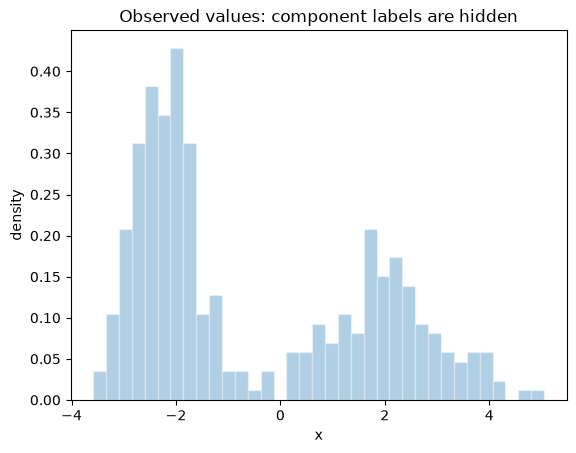

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.mixture import GaussianMixture

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
x = np.concatenate([
    rng.normal(-2.2, 0.65, 210),
    rng.normal(2.0, 1.05, 140),
]).reshape(-1, 1)

plt.hist(x[:,0], bins=35, density=True, alpha=0.35, edgecolor="white")
plt.xlabel("x"); plt.ylabel("density")
plt.title("Observed values: component labels are hidden")
plt.show()

## Question 1 — Interpret a fitted mixture (15 minutes)

Write the code to construct and fit a two-component GaussianMixture with n_init=10 and the supplied random state. Build a table of fitted weights, means and standard deviations, sorted by mean. Useful attributes: weights_, means_, covariances_; in this one-dimensional task, flatten the arrays and take the square root of variances. Report these three parameter types and explain why component numbers are arbitrary. Keep your explanation to one short paragraph.

In [50]:
# TODO: construct and fit gmm, then build summary as specified above.
# Keep component weights/means/standard deviations aligned when sorting.
gmm = GaussianMixture(
  n_components=2,
  covariance_type="full",
  n_init=10,
  random_state=RANDOM_STATE,
)
gmm.fit(x)

# Write the fitting and table-building statements here.
summary = pd.DataFrame({
  "weights": gmm.weights_,
  "means": gmm.means_.ravel(),
  "sd": np.sqrt(gmm.covariances_.ravel()),
}).sort_values("means")
display(summary.round(3))


,weights,means,sd
0,0.596,-2.237,0.564
1,0.404,1.998,1.123


### Write your answer — Question 1

For component 0, we obtained weights=0.596, means=-2.237, and sd=0.564, and for component 1, we obtained weights=0.404, means=1.998, and sd=1.123. A weight of 0.596 for component 0 means about 60% of the data is attributed to component 0, and a weight of 0.404 for component 1 means about 40% of the data is attributed to component 1.

Weight is prior mixture mass, mean gives location, and sd gives spread in x units. 

Component numbers are arbitrary because EM randomly assigns component numbers to the components. Nothing in the data tells the algorithm which component is 0 or 1. Components obtains their number by whichever order the algorithm decides to label first. In this case, the left component is labelled 0 while the right component is labelled 1.

## Question 2 — Find uncertain observations (15 minutes)

Compute responsibilities for the supplied probe grid. Find the most uncertain row programmatically by minimising the largest responsibility in each row (np.max with axis=1, then np.argmin). Also identify the most confident row. For two components, the most uncertain row has responsibilities closest to [0.5,0.5]. Report both responsibility vectors, explain why weights and component densities matter, and give one use for retaining soft membership. Do not hard-code a row index.

In [ ]:
probe_grid = np.linspace(-2.5, 2.5, 21).reshape(-1, 1)
# TODO: obtain the (n, 2) responsibility matrix, reduce across components,
# and select the uncertain and confident indices without hard-coding them.
probe_r = gmm.predict_proba(probe_grid)
confidence = probe_r.max(axis=1)
chosen_row = np.argmin(confidence)
confident_row = np.argmax(confidence)
for label, index in [('most uncertain', chosen_row), ('most confident', confident_row)]:
    print(label, probe_grid[index], probe_r[index])
assert np.allclose(probe_r.sum(axis=1), 1)
assert confidence[chosen_row] <= confidence[confident_row]


most uncertain [-0.75] [0.64348655 0.35651345]
most confident [2.5] [1.48966598e-15 1.00000000e+00]


### Write your answer — Question 2

The most uncertain grid point is at x=-0.75 with responsibilities [0.643, 0.357], while the most confident is at x=2.5 with responsibilities [1.5e-15, 1]. As expected, the most uncertain row has responsibilities closest to [0.5, 0.5].

Component weights and densities are important because they determine each component's weighted density, which is then used to calculate the final responsibility vector at a particular point x. Thus, in certain cases, components with a smaller weight can still have a higher responsibility if its density at a point is sufficiently large, which demonstrates that responsibilities depend on both the component weights and densities, rather than just positions of the component means.

Soft membership is useful because it keeps the uncertain values, which allows us to manually evaluate the responsibilities at a particular point, rather than hard labelling a point into a particular component. For example, point x=-0.75 can be evaluated for review because the model is uncertain, whereas a hard label would've marked it as part of a particular component. 

## Question 3 — Density and model-count evidence (20 minutes)

Run the supplied density plot. Write a loop fitting component counts 1 through 5, with n_init=10 and the same random state. Collect each count, BIC and AIC in a results table and select the minimum-BIC row programmatically. Briefly explain how the weighted densities form the mixture, why density is not point probability, and why the BIC-preferred count is not proof of natural groups. Cite the selected BIC and one alternative.

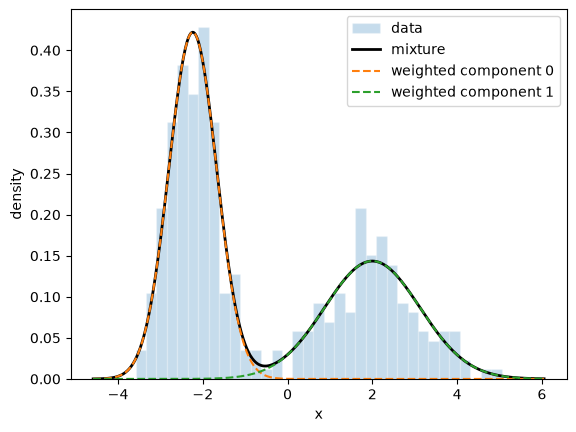

,components,BIC,AIC
0,1,1569.5,1561.8
1,2,1276.3,1257.0
2,3,1293.0,1262.1
3,4,1308.8,1266.4
4,5,1325.6,1271.6


BIC-preferred component count: 2


In [43]:
grid = np.linspace(x.min()-1, x.max()+1, 500).reshape(-1,1)
mixture_density = np.exp(gmm.score_samples(grid))
grid_resp = gmm.predict_proba(grid)
weighted_components = grid_resp * mixture_density[:,None]

plt.hist(x[:,0], bins=35, density=True, alpha=0.25, edgecolor="white", label="data")
plt.plot(grid[:,0], mixture_density, color="black", linewidth=2, label="mixture")
for k in range(2):
    plt.plot(grid[:,0], weighted_components[:,k], "--", label=f"weighted component {k}")
plt.xlabel("x"); plt.ylabel("density"); plt.legend(); plt.show()

# TODO: write the model-comparison loop and create criteria with columns
# components, BIC, AIC. Use candidate.bic(x) and candidate.aic(x).
rows = []
for components in range(1, 6):
    candidate = GaussianMixture(
        n_components=components,
        n_init=10,
        random_state=RANDOM_STATE,
    )
    candidate.fit(x)
    rows.append((components, candidate.bic(x), candidate.aic(x)))
criteria = pd.DataFrame(rows, columns=["components", "BIC", "AIC"])
best_components  =int(criteria.loc[criteria["BIC"].idxmin(), "components"])
display(criteria.round(1))
print('BIC-preferred component count:', best_components)


### Write your answer — Question 3

Density is curve height. Weighted densities are the products of each component's density curve and its weight. The weighted densities are added together at each value of x, and the mixture represents the combined contribution of all components.

The height of a density curve at a particular x is not the probability of observing exactly that value. For continuous variables, the probability of observing one exact point is zero. Probability is obtained from the area under the density curve over an interval, which is why a density cannot be a point probability.

BIC compares models by balancing the number of components it should have to model the complexity of the datatse. Model with the lowest BIC is preferred among the models tested, but this doesn't prove that the corresponding number of components represents the true number of natural groups in data. Multiple components can be used to model the distribution of a single natural group.

The selected model has the lowest BIC of 1276.3 for 2 components. For comparison, the model with 3 components has a BIC of 1293, a higher BIC than 2 components. The higher BIC for 3 components means its slightly better fit isn't enough to offset the added complexity, so 2 components gives the better trade-off. Lower is better because BIC balances negative twice log-likelihood against a parameter-count penalty.

In [44]:
def normal_pdf(values, mean, sd):
    return np.exp(-0.5*((values-mean)/sd)**2)/(np.sqrt(2*np.pi)*sd)
values=x[:,0]
initial=(np.array([0.5,0.5]),np.array([-1.5,1.5]),np.array([1.2,1.2]))

## Question 4 — Build one EM iteration (25 minutes)

First calculate by hand the responsibilities from weighted densities [0.12,0.08]. Complete and run e_step before m_step. Then implement the weighted parameter updates. Shapes: responsibilities (n,2), values[:,None] (n,1), component counts (2,). The formulas are weights=N_k/n, mean_k=sum(r_ik*x_i)/N_k, variance_k=sum(r_ik*(x_i-new_mean_k)^2)/N_k. Explain what is fixed in each step and use the row-sum and weight-sum checks to validate your implementation.

In [45]:
def e_step(values, weights, means, sds):
    weighted=np.column_stack([weights[k]*normal_pdf(values,means[k],sds[k]) for k in range(2)])
    # TODO: normalise across components, retaining the row dimension.
    return weighted / weighted.sum(axis=1, keepdims=True)
def m_step(values, responsibilities):
    counts=responsibilities.sum(axis=0)
    # TODO: weights = effective counts / number of observations.
    weights = counts / len(values)
    # TODO: weighted means; values[:,None] has shape (n,1).
    means = (responsibilities * values[:, None]).sum(axis=0) / counts
    # TODO: weighted squared deviations from the UPDATED means, divided by counts.
    variances = (responsibilities * (values[:, None] - means)**2).sum(axis=0) / counts
    return weights, means, np.sqrt(np.maximum(variances,1e-12))
r=e_step(values,*initial)
assert np.allclose(r.sum(axis=1),1)
print('First responsibilities:',r[:3])
one_update=m_step(values,r)
print('Updated weights, means, sds:',one_update)
assert np.isclose(one_update[0].sum(),1)
assert np.all(one_update[0]>=0) and np.all(one_update[2]>0)
print("Responsibility and parameter checks passed.")

First responsibilities: [[0.9847933  0.0152067 ]
 [0.99750668 0.00249332]
 [0.97253777 0.02746223]]
Updated weights, means, sds: (array([0.61696009, 0.38303991]), array([-2.11576969,  2.03341429]), array([0.81179779, 1.19026868]))
Responsibility and parameter checks passed.


### Write your answer — Question 4

Responsibilities from weighted densities: responsibility = weighted density / sum of all weighted densities
r0 = 0.12 / (0.12 + 0.08) = 0.12 / 0.2 = 0.6
r1 = 0.08 / 0.2 = 0.4
So the responsibility = [0.6, 0.4]

In each e_step, the model parameters (weights, means, sds) are fixed, and we compute the responsibilities for each observation. The row-sum check validates that the responsibilities for each observation sum to approximately 1, since each observation's responsibility must be distributed across all components. 

In each m_step, the responsibilities are fixed, and we use them to recompute the model parameters, including the weights, means, and sds. The weight-sum check validates that the mixture weights sum to approximately 1, since they represent the overall proportions of the components.

In [46]:
def run_em(start, steps=8):
    parameters=tuple(a.copy() for a in start);history=[]
    for iteration in range(steps+1):
        w,mu,sd=parameters
        density=sum(w[k]*normal_pdf(values,mu[k],sd[k]) for k in range(2))
        history.append([iteration,np.log(np.maximum(density,1e-300)).sum(),*mu])
        if iteration<steps: parameters=m_step(values,e_step(values,*parameters))
    return parameters,pd.DataFrame(history,columns=['iteration','log_likelihood','mean_0','mean_1'])
def parameter_table(parameters):
    w,mu,sd=parameters
    return pd.DataFrame({'weight':w,'mean':mu,'sd':sd}).sort_values('mean')

## Question 5 — Test initialisation and diagnose EM (15 minutes)

Before running, predict whether two identical starting components will separate under these deterministic updates. Compare start A from Q4 with start B below. Report likelihood changes and final parameters after sorting by mean. Compare with the fitted scikit-learn model from Q1. Explain whether rising/non-decreasing likelihood guarantees a globally best fit and why exact parameter equality is unnecessary.

In [47]:
start_b=(np.array([0.5,0.5]),np.array([0.,0.]),np.array([1.2,1.2]))
for label,start in [("A",initial),("B",start_b)]:
    params,history=run_em(start)
    print(label);display(history.round(3));display(parameter_table(params).round(3))
display(summary.round(3))

A


,iteration,log_likelihood,mean_0,mean_1
0,0,-745.050,-1.500,1.500
1,1,-645.056,-2.116,2.033
2,2,-625.172,-2.204,2.055
3,3,-623.703,-2.227,2.024
4,4,-623.535,-2.234,2.008
5,5,-623.509,-2.236,2.000
6,6,-623.504,-2.237,1.997
7,7,-623.503,-2.238,1.996
8,8,-623.503,-2.238,1.995


,weight,mean,sd
0,0.596,-2.238,0.563
1,0.404,1.995,1.126


B


,iteration,log_likelihood,mean_0,mean_1
0,0,-1028.912,0.000,0.000
1,1,-778.898,-0.526,-0.526
2,2,-778.898,-0.526,-0.526
3,3,-778.898,-0.526,-0.526
4,4,-778.898,-0.526,-0.526
5,5,-778.898,-0.526,-0.526
6,6,-778.898,-0.526,-0.526
7,7,-778.898,-0.526,-0.526
8,8,-778.898,-0.526,-0.526


,weight,mean,sd
0,0.5,-0.526,2.24
1,0.5,-0.526,2.24


,weights,means,sd
0,0.596,-2.237,0.564
1,0.404,1.998,1.123


### Write your answer — Question 5

I predict that two identical starting components would remain identical under deterministic EM updates, they would produce the same responsibilities for each observation. The M-step then receives identical responsibilities and produce identical updated parameters, so the components will not separate.

For start A and start B, the likelihood should be non-decreasing across EM iterations. The final parameters were sorted by component mean to make the comparison independent of component labels. The final parameters for start B were log_likelihood=-778.898, mean_0=-0.526, and mean_1=-0.526, compared with start A's parameters of log_likelihood=-623.503, mean_0=-2.238, and mean_1=1.995. Start A's final means (-2.238, 1.995) closely match the scikit-learn fit from Q1 (-2.237, 1.998), differing by less than 0.01 in each case, while start B never approached either.

A non-decreasing likelihood does not guarantee a globally best fit. EM improves the likelihood at each update but can converge to a local maximum rather than the global maximum. Therefore, increasing likelihood demonstrates improvement of the current solution, but does not prove that the solution is globally optimal.

The parameters do not need to be exactly equal to the scikit-learn model because different initialisations, convergence conditions, numerical precision, and implementation details can produce slightly different parameter estimates. Component labels are also arbitrary, so components should be compared after sorting by mean.

## Optional extensions

Complete these only after the core. Each is worth up to 5 bonus marks under the course policy; omitting either loses no core marks.

- Try a third asymmetric initialisation and compare convergence and final likelihood.
- Fit bootstrap samples with the supplied GaussianMixture API and compare means after sorting; describe sampling instability.

In [48]:
start_c = (np.array([0.5, 0.5]), np.array([-0.5, 0.5]), np.array([1.2, 1.2]))
params_c, history_c = run_em(start_c)
display(history_c.round(3))
display(parameter_table(params_c).round(3))

,iteration,log_likelihood,mean_0,mean_1
0,0,-961.024,-0.500,0.500
1,1,-748.959,-1.702,1.088
2,2,-713.943,-1.932,1.340
3,3,-655.390,-2.155,1.593
4,4,-628.366,-2.245,1.802
5,5,-624.562,-2.256,1.906
6,6,-623.755,-2.249,1.954
7,7,-623.556,-2.243,1.977
8,8,-623.514,-2.240,1.987


,weight,mean,sd
0,0.595,-2.240,0.560
1,0.405,1.987,1.136


With start C, means=[-0.5, 0.5], the run converged to log_likelihood=-623.514, mean_0=-2.240, and mean_1=1.987, matching start A (-623.503, -2.238, 1.995) more closely than start B (which stayed at -0.526/-0.526). Unlike start B, start C's two components weren't identical at initialization, so e_step could already assign slightly different responsibilities to points on each side. This shows that as long as assymmetry is broken, an off-centre start can converge to essentially the same solution as a well-chosen one.

In [49]:
n_boot = 30
boot_means = []

for i in range(n_boot):
    boot_x = rng.choice(x[:, 0], size=len(x), replace=True).reshape(-1, 1)
    boot_gmm = GaussianMixture(n_components=2, covariance_type="full",
                               n_init=10, random_state=RANDOM_STATE)
    boot_gmm.fit(boot_x)
    means_sorted = np.sort(boot_gmm.means_.ravel())
    boot_means.append(means_sorted)

boot_means = np.array(boot_means)

bootstrap_summary = pd.DataFrame({
    "mean": boot_means.mean(axis=0),
    "sd": boot_means.std(axis=0),
})
display(bootstrap_summary.round(3))

,mean,sd
0,-2.233,0.046
1,2.007,0.088


Across 30 bootstrap resamples, the left component has mean=-2.228 and sd=0.045, while the right component has mean=2.004 and sd=0.099. Both components have small sds, which indicates that the two-cluster structure is stable under resampling.

The right component's mean is somewhat less stable than the left's (sd 0.099 vs 0.045), which fits its original sd (1.123 vs 0.564). A more spread-out component gives the fit less certainty about exactly where its centre sits.